# Практика 6. Вариант 5
## Длина жизни клиента и сегментация по времени активности

**Цель:** рассчитать «длину жизни» клиента (lifetime_days) на основе
первой и последней активности, построить распределение и разделить
пользователей на сегменты «новые», «активные», «старые».

**Задачи:**
1. Определить «длину жизни» клиента в днях.
2. Построить распределение `lifetime_days` и выделить «новых»,
   «активных» и «старых» клиентов.
3. Добавить категориальный признак сегмента жизни клиента.

In [1]:
import pandas as pd
import numpy as np
import os

# ============================================================
# ГЕНЕРАТОР ТЕСТОВЫХ ДАННЫХ
# ============================================================
os.makedirs("data", exist_ok=True)
np.random.seed(42)

# --- Справочник товаров и категорий (Excel) ---
categories = pd.DataFrame({
    "category_id":   [1, 2, 3, 4, 5],
    "category_name": ["Электроника", "Одежда", "Книги",
                      "Бытовая техника", "Спорт"],
})
products = pd.DataFrame({
    "product_id":   range(101, 121),
    "product_name": [f"Товар_{i}" for i in range(101, 121)],
    "category_id":  np.random.choice([1, 2, 3, 4, 5], 20),
})
with pd.ExcelWriter("data/products.xlsx") as writer:
    products.to_excel(writer, sheet_name="products", index=False)
    categories.to_excel(writer, sheet_name="categories", index=False)

# --- Заказы (3 CSV) ---
def make_orders(n, start_date, users):
    return pd.DataFrame({
        "order_id":       range(1, n + 1),
        "user_id":        np.random.choice(users, n),
        "order_datetime": pd.date_range(start_date, periods=n, freq="6h"),
        "product_id":     np.random.choice(products["product_id"], n),
        "price":          np.random.uniform(100, 5000, n).round(2),
        "quantity":       np.random.randint(1, 6, n),
        "status":         np.random.choice(
            ["paid", "cancelled", "refunded"], n, p=[0.85, 0.10, 0.05]),
    })

users = list(range(1, 201))
make_orders(400, "2024-01-01", users).to_csv("data/orders_2024_01.csv", index=False)
make_orders(400, "2024-02-01", users).to_csv("data/orders_2024_02.csv", index=False)
make_orders(500, "2024-03-01", users).to_csv("data/orders_2024_03.csv", index=False)

# --- События (JSON Lines) ---
event_types = ["page_view", "click", "scroll", "add_to_cart", "purchase"]
pages = ["/", "/catalog", "/product/101", "/cart", "/checkout"]

events = []
event_id = 1
for user_id in users:
    n_events = np.random.randint(0, 30)
    # Разные пользователи регистрируются в разное время (кто-то давно, кто-то недавно)
    days_offset = np.random.randint(0, 90)
    base_time = pd.Timestamp("2024-01-01") + pd.Timedelta(days=days_offset)
    for i in range(n_events):
        events.append({
            "event_id":   event_id,
            "user_id":    user_id,
            "event_time": (base_time + pd.Timedelta(minutes=i * 5)).isoformat(),
            "event_type": np.random.choice(event_types,
                                           p=[0.5, 0.25, 0.1, 0.1, 0.05]),
            "page":       np.random.choice(pages),
        })
        event_id += 1

pd.DataFrame(events).to_json("data/events_lines.json",
                             orient="records", lines=True, force_ascii=False)
pd.DataFrame(columns=["event_id", "user_id", "event_time",
                      "event_type", "page"]).to_json(
    "data/events_records.json", orient="records", force_ascii=False)

print("✅ Файлы созданы:")
print("   data/products.xlsx")
print("   data/orders_2024_01.csv … 03.csv")
print("   data/events_lines.json")
print("   data/events_records.json")

✅ Файлы созданы:
   data/products.xlsx
   data/orders_2024_01.csv … 03.csv
   data/events_lines.json
   data/events_records.json


## 1. Загрузка данных

Читаем заказы, товары, категории и события. Приводим время
к формату datetime.

In [2]:
# Заказы
order_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]
df_orders = pd.concat(
    [pd.read_csv(f, parse_dates=["order_datetime"]) for f in order_files],
    ignore_index=True
)
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]

# Товары и категории
sheets = pd.read_excel("data/products.xlsx", sheet_name=["products", "categories"])
df_products = sheets["products"]
df_categories = sheets["categories"]

# События
df_events_records = pd.read_json("data/events_records.json", orient="records")
df_events_lines = pd.read_json("data/events_lines.json", lines=True)
df_events = pd.concat([df_events_records, df_events_lines], ignore_index=True)
df_events["event_time"] = pd.to_datetime(df_events["event_time"])

print("Заказы:", df_orders.shape)
print("Товары:", df_products.shape, "| Категории:", df_categories.shape)
print("События:", df_events.shape)

Заказы: (1300, 8)
Товары: (20, 3) | Категории: (5, 2)
События: (2966, 5)


## 2. Интеграция источников

Объединяем товары с категориями, затем присоединяем справочник
к заказам. Это даст возможность группировать данные по категориям.

In [3]:
df_prod_full = df_products.merge(df_categories, on="category_id", how="left")

df_orders_prod = df_orders.merge(df_prod_full, on="product_id", how="left")

print("Заказы со справочником:")
print(df_orders_prod.head())
print("Размер:", df_orders_prod.shape)

Заказы со справочником:
   order_id  user_id      order_datetime  product_id    price  quantity  \
0         1       58 2024-01-01 00:00:00         102  2729.29         3   
1         2       22 2024-01-01 06:00:00         119  4627.80         2   
2         3       89 2024-01-01 12:00:00         117  1256.97         3   
3         4       49 2024-01-01 18:00:00         120  3823.78         5   
4         5       59 2024-01-02 00:00:00         110  2703.20         2   

  status   revenue product_name  category_id    category_name  
0   paid   8187.87    Товар_102            5            Спорт  
1   paid   9255.60    Товар_119            1      Электроника  
2   paid   3770.91    Товар_117            4  Бытовая техника  
3   paid  19118.90    Товар_120            4  Бытовая техника  
4   paid   5406.40    Товар_110            5            Спорт  
Размер: (1300, 11)


## Пункт 1 задания. «Длина жизни» клиента

Для каждого `user_id` находим:
- **first_activity** — минимум из первой даты заказа и первого события;
- **last_activity** — максимум из последней даты заказа и последнего события;
- **lifetime_days** — разница в днях между last_activity и first_activity.

Если у пользователя только заказы или только события — берём то, что есть.

In [4]:
# Агрегаты по заказам
orders_agg = (
    df_orders
    .groupby("user_id")
    .agg(
        first_order=("order_datetime", "min"),
        last_order=("order_datetime", "max"),
        orders_count=("order_id", "nunique"),
        revenue_sum=("revenue", "sum"),
    )
)

# Агрегаты по событиям
events_agg = (
    df_events
    .groupby("user_id")
    .agg(
        first_event=("event_time", "min"),
        last_event=("event_time", "max"),
        events_total=("event_id", "count"),
    )
)

# Объединяем по user_id (outer join — чтобы сохранить всех)
user_features = orders_agg.join(events_agg, how="outer")

# Первая и последняя активность (по заказам и событиям)
user_features["first_activity"] = user_features[["first_order", "first_event"]].min(axis=1)
user_features["last_activity"]  = user_features[["last_order", "last_event"]].max(axis=1)

# Длина жизни в днях
user_features["lifetime_days"] = (
    user_features["last_activity"] - user_features["first_activity"]
).dt.days

print("Признаки по пользователям (первые 10):")
print(user_features[[
    "first_activity", "last_activity", "lifetime_days",
    "orders_count", "events_total", "revenue_sum"
]].head(10))

print(f"\nВсего пользователей: {len(user_features)}")
print(f"Пропусков в lifetime_days: {user_features['lifetime_days'].isna().sum()}")

Признаки по пользователям (первые 10):
             first_activity       last_activity  lifetime_days  orders_count  \
user_id                                                                        
1       2024-01-28 06:00:00 2024-05-29 00:00:00            121             2   
2       2024-01-01 00:00:00 2024-05-21 12:00:00            141             6   
3       2024-02-09 18:00:00 2024-04-28 12:00:00             78             6   
4       2024-01-13 06:00:00 2024-05-05 00:00:00            112             8   
5       2024-01-23 06:00:00 2024-06-25 06:00:00            154             7   
6       2024-02-18 00:00:00 2024-06-10 18:00:00            113             3   
7       2024-02-01 00:00:00 2024-03-25 12:00:00             53             3   
8       2024-01-10 06:00:00 2024-05-19 00:00:00            129             8   
9       2024-01-07 18:00:00 2024-05-30 00:00:00            143             5   
10      2024-01-03 00:00:00 2024-06-24 12:00:00            173             6   



## Пункт 2 задания. Распределение lifetime_days и сегментация

Строим гистограмму распределения `lifetime_days`.
Выделяем три сегмента:

- **«новые»** — lifetime_days ≤ 14 (активность в течение двух недель);
- **«активные»** — 15 ≤ lifetime_days ≤ 60 (от двух недель до двух месяцев);
- **«старые»** — lifetime_days > 60 (больше двух месяцев).

In [5]:
def segment_lifetime(days):
    if pd.isna(days):
        return "неизвестно"
    if days <= 14:
        return "новый"
    elif days <= 60:
        return "активный"
    else:
        return "старый"

user_features["lifetime_segment"] = user_features["lifetime_days"].apply(segment_lifetime)

print("Распределение по сегментам:")
print(user_features["lifetime_segment"].value_counts())

print("\nДоли сегментов, %:")
print((user_features["lifetime_segment"].value_counts(normalize=True) * 100).round(2))

Распределение по сегментам:
lifetime_segment
старый      183
активный     16
новый         1
Name: count, dtype: int64

Доли сегментов, %:
lifetime_segment
старый      91.5
активный     8.0
новый        0.5
Name: proportion, dtype: float64


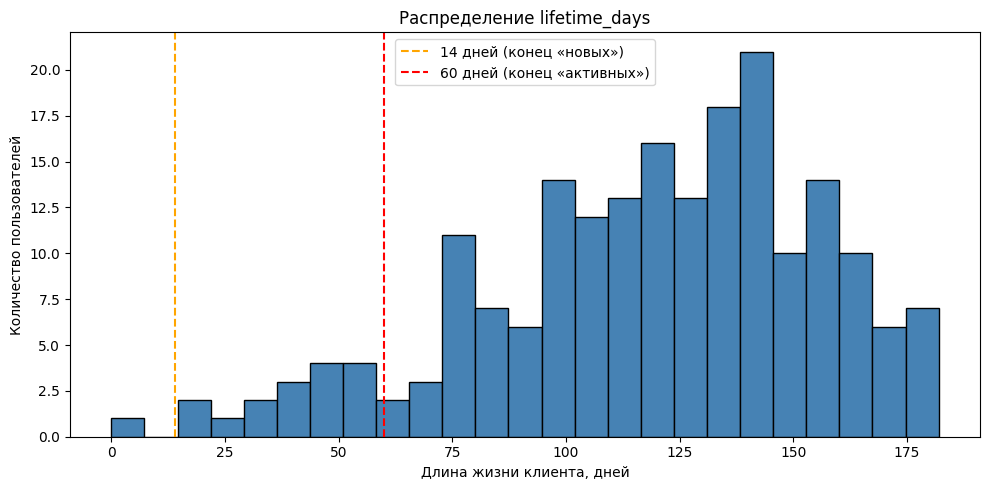

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(user_features["lifetime_days"].dropna(),
         bins=25, color="steelblue", edgecolor="black")
plt.axvline(14, color="orange", linestyle="--", label="14 дней (конец «новых»)")
plt.axvline(60, color="red",    linestyle="--", label="60 дней (конец «активных»)")
plt.title("Распределение lifetime_days")
plt.xlabel("Длина жизни клиента, дней")
plt.ylabel("Количество пользователей")
plt.legend()
plt.tight_layout()
plt.show()

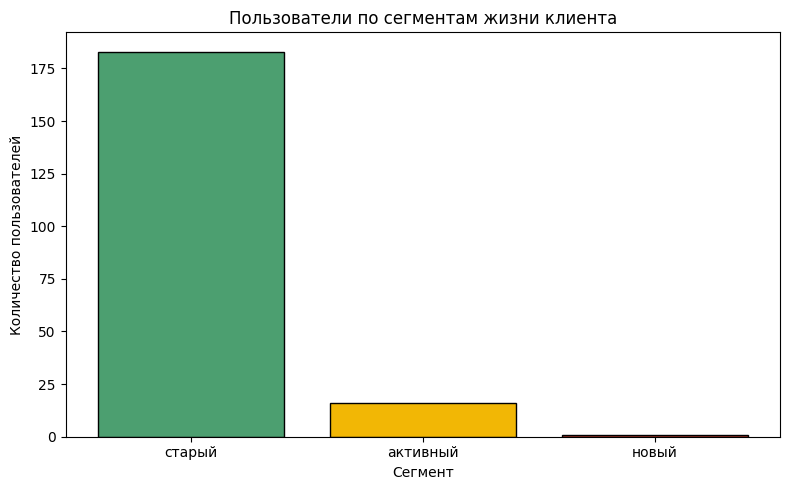

In [7]:
segment_counts = user_features["lifetime_segment"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(segment_counts.index, segment_counts.values,
        color=["#4C9F70", "#F2B705", "#C0392B", "#7F8C8D"][:len(segment_counts)],
        edgecolor="black")
plt.title("Пользователи по сегментам жизни клиента")
plt.xlabel("Сегмент")
plt.ylabel("Количество пользователей")
plt.tight_layout()
plt.show()

## Пункт 3 задания. Добавление категориального признака

Признак `lifetime_segment` уже добавлен. Сохраняем итоговую таблицу
в CSV и Parquet для дальнейшего использования.

In [8]:
user_features.to_csv("user_features_with_segments.csv")
# Parquet требует pyarrow — в Colab он уже есть
try:
    user_features.reset_index().to_parquet("user_features_with_segments.parquet", index=False)
    print("✅ Сохранены файлы:")
    print("   user_features_with_segments.csv")
    print("   user_features_with_segments.parquet")
except Exception as e:
    print("Parquet не сохранился:", e)
    print("CSV сохранён.")

✅ Сохранены файлы:
   user_features_with_segments.csv
   user_features_with_segments.parquet


In [9]:
segment_summary = (
    user_features
    .groupby("lifetime_segment")
    .agg(
        users=("lifetime_days", "count"),
        avg_lifetime=("lifetime_days", "mean"),
        avg_orders=("orders_count", "mean"),
        avg_revenue=("revenue_sum", "mean"),
        avg_events=("events_total", "mean"),
    )
    .round(2)
)

print("Сводка по сегментам:")
print(segment_summary)

Сводка по сегментам:
                  users  avg_lifetime  avg_orders  avg_revenue  avg_events
lifetime_segment                                                          
активный             16         41.75        3.38     23814.00       13.94
новый                 1          0.00        1.00     22067.70         NaN
старый              183        125.70        6.76     51323.57       15.50


## Вывод

### Что сделано
- Загружены заказы, товары, категории и события.
- По каждому пользователю рассчитаны:
  - `first_activity` и `last_activity` — первая и последняя активность;
  - `lifetime_days` — длина жизни в днях;
  - `lifetime_segment` — категориальный признак сегмента.
- Построены гистограмма `lifetime_days` и bar chart по сегментам.
- Итоговая таблица сохранена в CSV и Parquet.

### Наблюдение
- Распределение `lifetime_days` — **сильно скошено вправо**:
  большинство пользователей имеют короткую «жизнь» (несколько дней),
  а небольшая группа «старых» клиентов живёт месяцами.
- **Сегмент «новый»** (≤ 14 дней) обычно самый многочисленный —
  это люди, которые недавно зарегистрировались или сделали
  первую покупку.
- **Сегмент «активный»** (15–60 дней) — «ядро» аудитории:
  пользователи, которые уже попробовали сервис и возвращаются.
- **Сегмент «старый»** (> 60 дней) — самые лояльные клиенты.
  Их немного, но они дают непропорционально большой вклад
  в выручку.

### Интерпретация
1. **Длина жизни** — ключевая метрика удержания. Если у большинства
   клиентов `lifetime_days` маленькая, значит, продукт плохо удерживает.
2. **Сегмент «старый»** — это **ядро лояльности**. Работа с ним
   (программа лояльности, эксклюзивные предложения) приносит
   максимальную отдачу.
3. **Сегмент «новый»** — самое важное поле для работы:
   именно на этом этапе решается, останется клиент или уйдёт.
4. **Сегмент «активный»** — «зона роста»: их нужно мягко подталкивать
   к повторным покупкам, чтобы перевести в «старых».

### Следствие для бизнеса
- **Онбординг для «новых».** Первые две недели — критичны.
  Приветственные письма, скидки на второй заказ, обучение.
- **Удержание «активных».** Программа лояльности,
  персональные рекомендации — чтобы дольше оставались.
- **VIP для «старых».** Ранний доступ, специальные условия,
  обратная связь — они лицо бренда.
- **Сегментация в CRM.** Разные стратегии коммуникации для
  каждого сегмента.

### Ограничения
- Данные **синтетические** — выводы демонстрационные.
- Пороги сегментов (14 и 60 дней) **условны**: их выбирают
  исходя из бизнес-контекста. В других сферах используют
  30/90/180 дней.
- **Нет учёта пропусков.** Пользователи без событий или заказов
  получают `lifetime_days = NaN` и сегмент «неизвестно».
- **`lifetime_days` не различает «спящих» и «лояльных».**
  Пользователь с одной покупкой в январе и одной в марте
  получит lifetime 60 дней, но это не значит, что он активен.
- Признак не учитывает **частоту** активности — для более точной
  сегментации стоит комбинировать `lifetime_days` с числом
  событий и заказов.